# Unit 8 – Creating Parse Trees
**Module:** Intelligent Agents (IA_PCOM7E, July 2026) · **Student:** Adil Aljasmi

**Activity brief (Unit 8):** *Create a constituency-based parse tree for the following phrases:*
1. *The government raised interest rates.*
2. *The internet gives everyone a voice.*
3. *The man saw the dog with the telescope.*

**Approach.** A constituency tree groups words into nested phrases (noun phrases, verb phrases, prepositional phrases) defined by a context-free grammar (Jurafsky & Martin, 2026). I wrote a small grammar that covers the three sentences, a chart-style parser that finds **every** tree the grammar allows, and a plotting function that draws them. Using a parser rather than drawing by hand checks that each tree really follows from the grammar and shows where a sentence is ambiguous. Only the Python standard library and matplotlib are used.

**Labels:** S = sentence, NP = noun phrase, VP = verb phrase, PP = prepositional phrase, Det = determiner, N = noun, Pro = pronoun, V = verb, P = preposition.

In [1]:
from functools import lru_cache
from itertools import product

# Context-free grammar (phrase rules) and lexicon (word -> part of speech)
GRAMMAR = {
    "S":  [("NP", "VP")],
    "NP": [("Det", "N"), ("N", "N"), ("Pro",), ("NP", "PP")],   # N N = noun compound ('interest rates')
    "VP": [("V", "NP"), ("V", "NP", "NP"), ("VP", "PP")],        # V NP NP = ditransitive ('gives everyone a voice')
    "PP": [("P", "NP")],
}
LEXICON = {
    "Det": {"the", "a"},
    "N":   {"government", "interest", "rates", "internet", "voice", "man", "dog", "telescope", "park", "hill", "bench", "garden"},
    "Pro": {"everyone"},
    "V":   {"raised", "gives", "saw"},
    "P":   {"with", "in", "on", "near"},
}

def splits(i, j, k):
    """All ways to cut words[i:j] into k non-empty, contiguous parts."""
    if k == 1:
        yield [(i, j)]
        return
    for m in range(i + 1, j - k + 2):
        for rest in splits(m, j, k - 1):
            yield [(i, m)] + rest

def parse(sentence, grammar=GRAMMAR, lexicon=LEXICON):
    """Return every parse tree for the sentence (tree = (label, child, ...); leaves are words)."""
    words = tuple(sentence.lower().rstrip(".").split())

    @lru_cache(maxsize=None)
    def trees(sym, i, j):
        out = []
        if sym in lexicon:                       # part-of-speech node
            if j == i + 1 and words[i] in lexicon[sym]:
                out.append((sym, words[i]))
            return tuple(out)
        for rhs in grammar.get(sym, []):
            for parts in splits(i, j, len(rhs)):
                kids = [trees(s, a, b) for s, (a, b) in zip(rhs, parts)]
                for combo in product(*kids):
                    out.append((sym, *combo))
        return tuple(out)

    return list(trees("S", 0, len(words)))

def bracket(t):
    return t if isinstance(t, str) else "(" + t[0] + " " + " ".join(bracket(c) for c in t[1:]) + ")"

SENTENCES = ["The government raised interest rates.",
             "The internet gives everyone a voice.",
             "The man saw the dog with the telescope."]
PARSES = {s: parse(s) for s in SENTENCES}
for s, ts in PARSES.items():
    print(f"{s}  ->  {len(ts)} parse(s)")
    for t in ts:
        print("   ", bracket(t))

The government raised interest rates.  ->  1 parse(s)
    (S (NP (Det the) (N government)) (VP (V raised) (NP (N interest) (N rates))))
The internet gives everyone a voice.  ->  1 parse(s)
    (S (NP (Det the) (N internet)) (VP (V gives) (NP (Pro everyone)) (NP (Det a) (N voice))))
The man saw the dog with the telescope.  ->  2 parse(s)
    (S (NP (Det the) (N man)) (VP (V saw) (NP (NP (Det the) (N dog)) (PP (P with) (NP (Det the) (N telescope))))))
    (S (NP (Det the) (N man)) (VP (VP (V saw) (NP (Det the) (N dog))) (PP (P with) (NP (Det the) (N telescope)))))


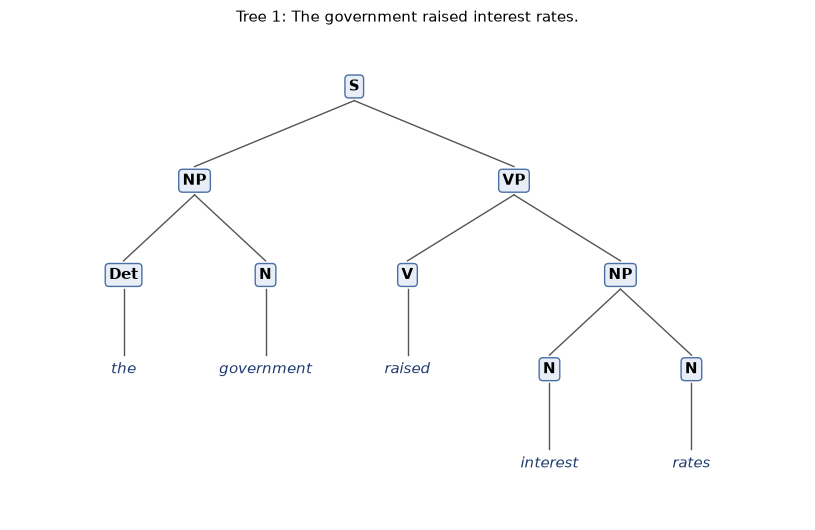

In [2]:
import matplotlib.pyplot as plt

def draw_tree(tree, title, path=None, ax=None, highlight=("PP",)):
    """Leaves get evenly spaced x positions; each phrase sits above the middle of its children."""
    pos, edges, nodes = {}, [], []
    counter = [0]

    def layout(t, depth, node_id):
        if isinstance(t, str):                                   # a word
            x = counter[0]; counter[0] += 1
            nodes.append((node_id, x, depth, t, "word"))
            return x
        xs = [layout(c, depth + 1, node_id + (k,)) for k, c in enumerate(t[1:])]
        x = (xs[0] + xs[-1]) / 2
        for k in range(len(xs)):
            edges.append((node_id, node_id + (k,)))
        nodes.append((node_id, x, depth, t[0], "phrase"))
        return x

    layout(tree, 0, ())
    for nid, x, d, *_ in nodes:
        pos[nid] = (x, -d)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(1.25 * counter[0] + 2, 0.9 * (max(-y for _, y in pos.values()) + 2)))
    for a, b in edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1 - 0.15, y2 + 0.15], color="#555", lw=1)
    for nid, x, d, label, kind in nodes:
        if kind == "word":
            ax.text(x, -d, label, ha="center", va="center", fontsize=11, style="italic", color="#1f3b70")
        else:
            fc = "#fde3c8" if label in highlight else "#e8eef7"
            ax.text(x, -d, label, ha="center", va="center", fontsize=11, weight="bold",
                    bbox=dict(boxstyle="round,pad=0.25", fc=fc, ec="#4a6fa5"))
    ax.set_xlim(-0.8, counter[0] - 0.2); ax.set_ylim(min(y for _, y in pos.values()) - 0.6, 0.6)
    ax.axis("off"); ax.set_title(title, fontsize=11)
    if own:
        fig.tight_layout()
        if path:
            fig.savefig(path, dpi=150)
        plt.show()

t1, = PARSES[SENTENCES[0]]
draw_tree(t1, "Tree 1: The government raised interest rates.", "8.Unit08 Tree 1 - The government raised interest rates.png")

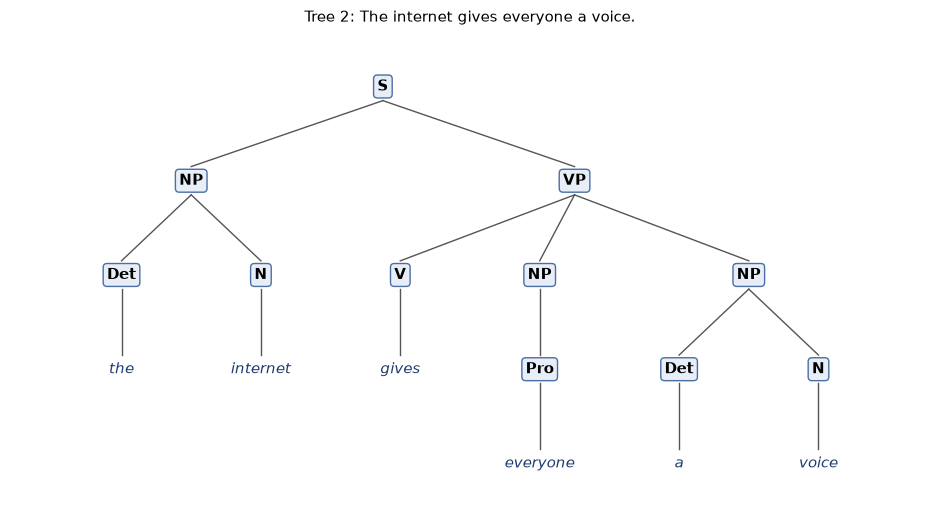

In [3]:
t2, = PARSES[SENTENCES[1]]
draw_tree(t2, "Tree 2: The internet gives everyone a voice.", "8.Unit08 Tree 2 - The internet gives everyone a voice.png")

### Sentence 3 is ambiguous: two trees
The prepositional phrase *with the telescope* can attach in two places:
- **3a – attached to the verb phrase:** the man **used** the telescope to see the dog (the PP says *how* he saw).
- **3b – attached to the noun phrase:** the man saw **the dog that had** the telescope (the PP describes *which* dog).

The grammar allows both, so the parser returns both. Grammar alone cannot choose; context or word statistics are needed (Hindle & Rooth, 1993).

3a: VP attachment (instrument)
    (S (NP (Det the) (N man)) (VP (VP (V saw) (NP (Det the) (N dog))) (PP (P with) (NP (Det the) (N telescope)))))


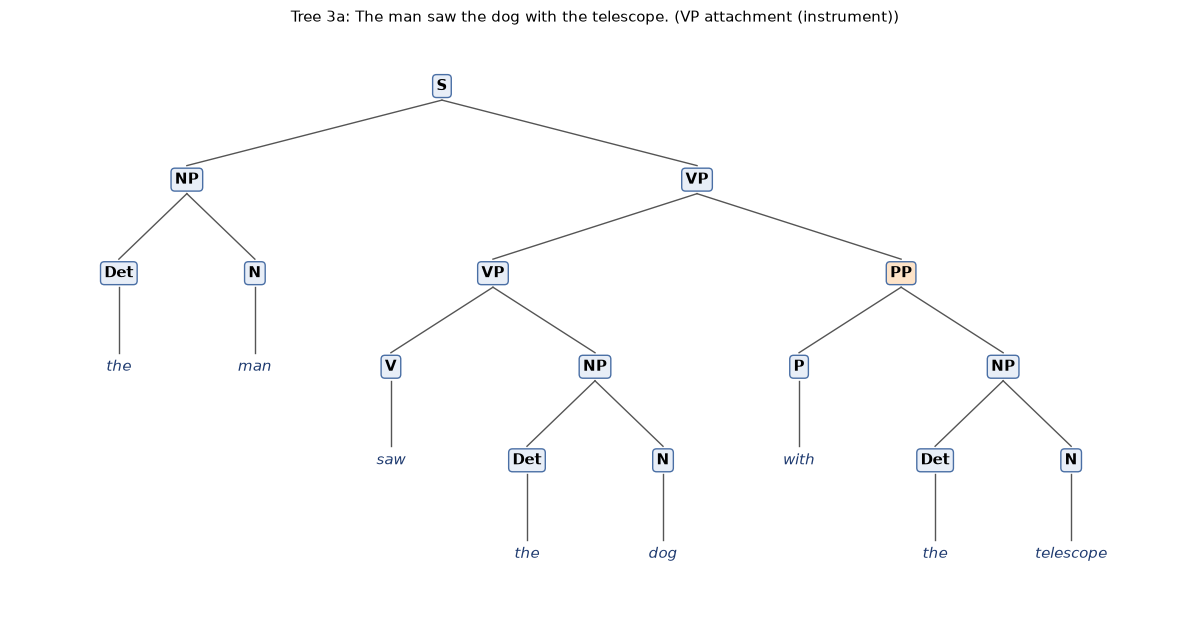

3b: NP attachment (modifier)
    (S (NP (Det the) (N man)) (VP (V saw) (NP (NP (Det the) (N dog)) (PP (P with) (NP (Det the) (N telescope))))))


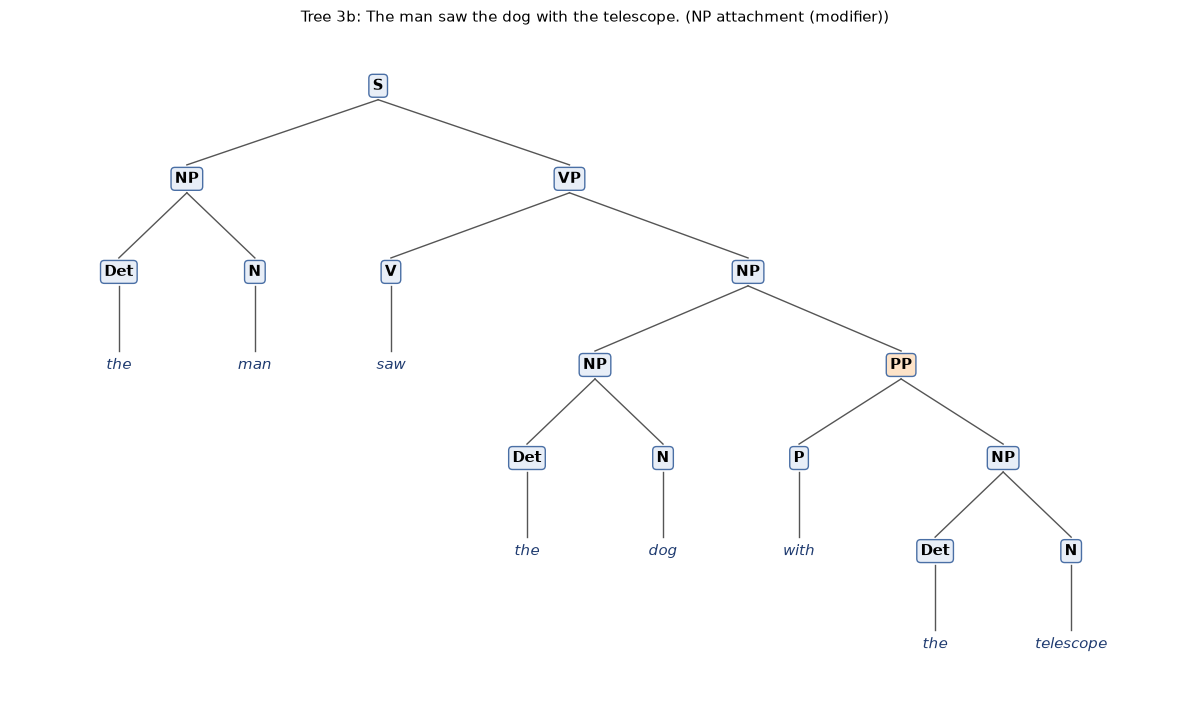

In [4]:
def attachment(t):
    vp = t[2]
    return "VP attachment (instrument)" if vp[0] == "VP" and vp[-1][0] == "PP" and vp[1][0] == "VP" else "NP attachment (modifier)"

t3 = sorted(PARSES[SENTENCES[2]], key=lambda t: attachment(t), reverse=True)   # VP first, then NP
for tag, t in zip("ab", t3):
    kind = attachment(t)
    print(f"3{tag}: {kind}\n    {bracket(t)}")
    draw_tree(t, f"Tree 3{tag}: The man saw the dog with the telescope. ({kind})",
              f"8.Unit08 Tree 3{tag} - The man saw the dog with the telescope ({kind.split(' (')[0]}).png")

## Experiments

In [5]:
# E1: remove the ditransitive rule VP -> V NP NP. Can the grammar still parse sentence 2?
no_ditrans = {**GRAMMAR, "VP": [r for r in GRAMMAR["VP"] if r != ("V", "NP", "NP")]}
print("E1 parses of sentence 2 without VP -> V NP NP:", len(parse(SENTENCES[1], grammar=no_ditrans)))

# E2: remove the noun-compound rule NP -> N N. Can it still parse sentence 1?
no_compound = {**GRAMMAR, "NP": [r for r in GRAMMAR["NP"] if r != ("N", "N")]}
print("E2 parses of sentence 1 without NP -> N N   :", len(parse(SENTENCES[0], grammar=no_compound)))

# E3: remove the NP -> NP PP rule. Is sentence 3 still ambiguous?
no_np_pp = {**GRAMMAR, "NP": [r for r in GRAMMAR["NP"] if r != ("NP", "PP")]}
print("E3 parses of sentence 3 without NP -> NP PP :", len(parse(SENTENCES[2], grammar=no_np_pp)))

E1 parses of sentence 2 without VP -> V NP NP: 0
E2 parses of sentence 1 without NP -> N N   : 0
E3 parses of sentence 3 without NP -> NP PP : 1


0 PP(s):    1 parses   Catalan(1) =    1   match
1 PP(s):    2 parses   Catalan(2) =    2   match
2 PP(s):    5 parses   Catalan(3) =    5   match
3 PP(s):   14 parses   Catalan(4) =   14   match
4 PP(s):   42 parses   Catalan(5) =   42   match
5 PP(s):  132 parses   Catalan(6) =  132   match
6 PP(s):  429 parses   Catalan(7) =  429   match


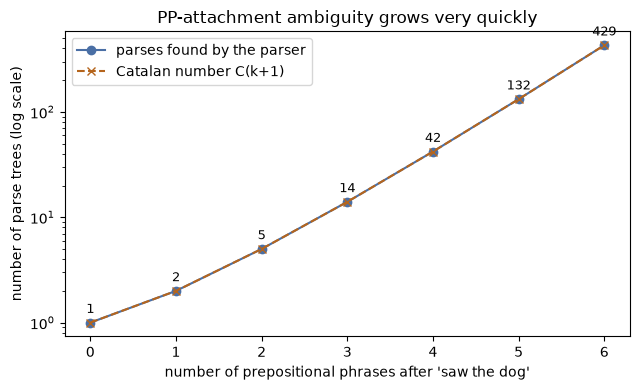

In [6]:
# E4: add more prepositional phrases and count the trees.
# Church & Patil (1982) showed such counts follow the Catalan numbers.
from math import comb
PPS = ["with the telescope", "in the park", "on the bench", "near the garden", "with the dog", "in the garden"]
catalan = lambda n: comb(2 * n, n) // (n + 1)
rows = []
for k in range(0, len(PPS) + 1):
    s = "The man saw the dog " + " ".join(PPS[:k])
    n = len(parse(s))
    rows.append((k, n, catalan(k + 1)))
    print(f"{k} PP(s): {n:>4} parses   Catalan({k+1}) = {catalan(k+1):>4}   {'match' if n == catalan(k+1) else 'DIFFERENT'}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ks, ns, cs = zip(*rows)
ax.plot(ks, ns, "o-", label="parses found by the parser", color="#4a6fa5")
ax.plot(ks, cs, "x--", label="Catalan number C(k+1)", color="#b5651d")
ax.set_yscale("log"); ax.set_xlabel("number of prepositional phrases after 'saw the dog'")
ax.set_ylabel("number of parse trees (log scale)")
ax.set_title("PP-attachment ambiguity grows very quickly")
for k, n in zip(ks, ns):
    ax.annotate(str(n), (k, n), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
ax.legend(); fig.tight_layout(); fig.savefig("8.Unit08 PP attachment growth.png", dpi=150); plt.show()

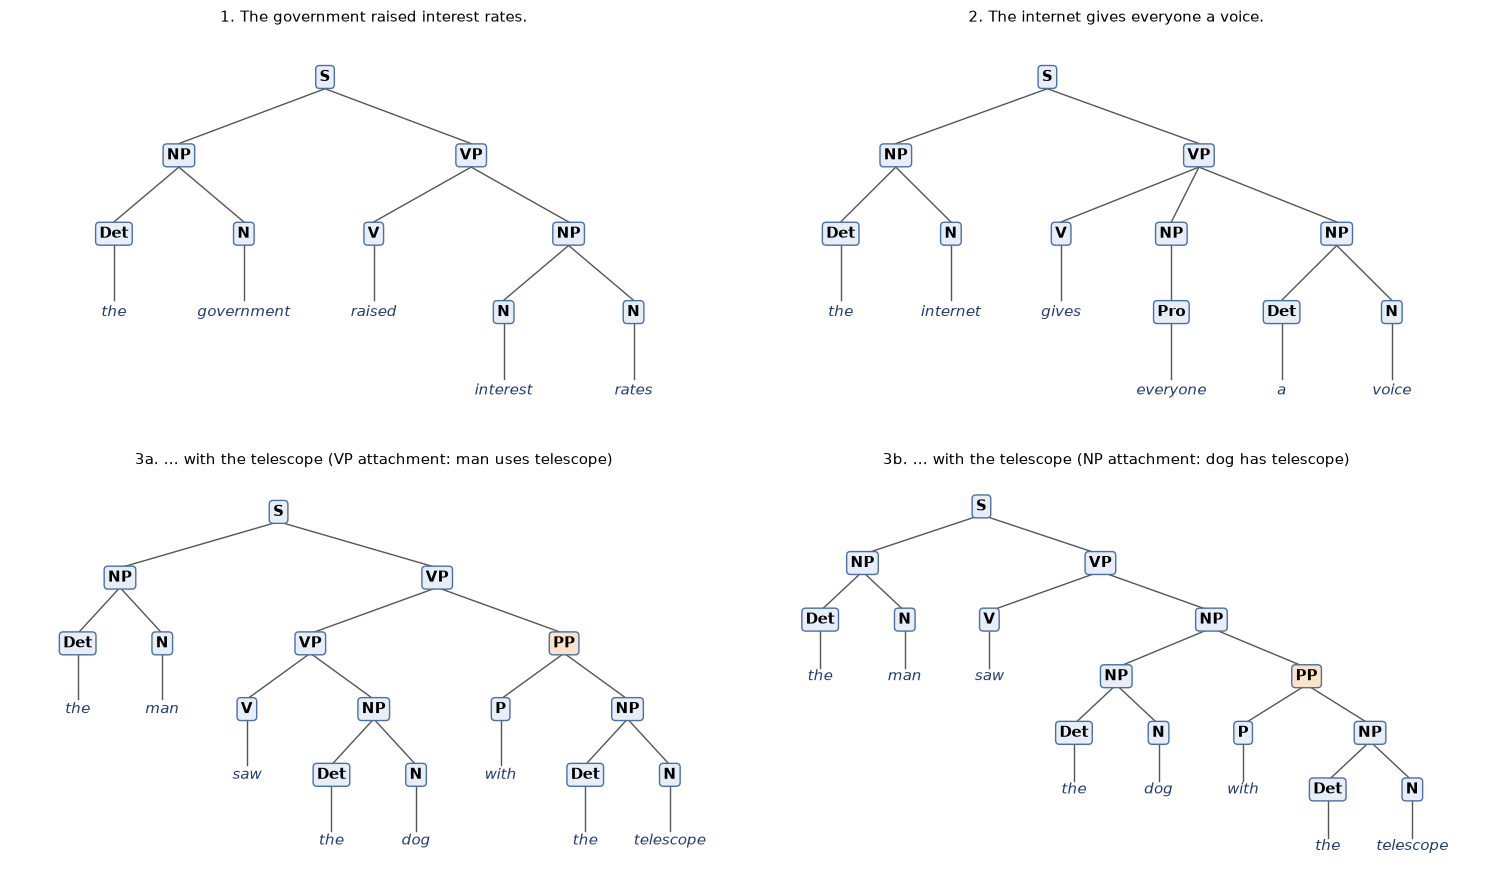

In [7]:
# One combined figure for the e-portfolio page
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
draw_tree(t1, "1. The government raised interest rates.", ax=axes[0, 0])
draw_tree(t2, "2. The internet gives everyone a voice.", ax=axes[0, 1])
draw_tree(t3[0], "3a. ... with the telescope (VP attachment: man uses telescope)", ax=axes[1, 0])
draw_tree(t3[1], "3b. ... with the telescope (NP attachment: dog has telescope)", ax=axes[1, 1])
fig.tight_layout(); fig.savefig("8.Unit08 All parse trees.png", dpi=150); plt.show()

## Findings

**The trees.**
1. *The government raised interest rates* has one tree: `(S (NP (Det the) (N government)) (VP (V raised) (NP (N interest) (N rates))))`. *Interest rates* is a noun compound, so both nouns sit inside one object NP.
2. *The internet gives everyone a voice* has one tree, with the verb taking two objects: `(VP (V gives) (NP (Pro everyone)) (NP (Det a) (N voice)))`. *Everyone* is the indirect object (the receiver) and *a voice* is the direct object (the thing given).
3. *The man saw the dog with the telescope* has **two** trees. In 3a the PP attaches to the VP (the man uses the telescope). In 3b it attaches to the object NP (the dog has the telescope).

**What the experiments show.**
- Each rule is needed for a specific sentence. Without `VP → V NP NP` sentence 2 gets 0 parses (E1). Without `NP → N N` sentence 1 gets 0 parses (E2). Without `NP → NP PP` sentence 3 drops to a single tree, the instrument reading (E3). So the ambiguity comes from one grammar rule, and removing it also removes a correct reading.
- Ambiguity grows very fast. With 0 to 6 PPs after *saw the dog*, the parser found 1, 2, 5, 14, 42, 132 and 429 trees, exactly the Catalan numbers reported by Church & Patil (1982) (E4). Six short phrases already give 429 possible structures.

**Reflection.** Drawing the first two trees by hand was straightforward. Building the grammar showed me that a parser is only as good as its rules: one missing rule makes a correct sentence unparseable. The third sentence was the most useful, because syntax alone cannot decide whether the man or the dog has the telescope. For an intelligent agent that reads text, this means a parse tree is not enough. The agent also needs context, world knowledge or statistics about which words usually go together (Hindle & Rooth, 1993) to choose the right meaning. Large treebanks such as the Penn Treebank (Marcus, Santorini & Marcinkiewicz, 1993) were built partly to learn these preferences from data.

## References
Church, K. & Patil, R. (1982) Coping with syntactic ambiguity or how to put the block in the box on the table. *American Journal of Computational Linguistics* 8(3–4): 139–149.

Hindle, D. & Rooth, M. (1993) Structural ambiguity and lexical relations. *Computational Linguistics* 19(1): 103–120.

Jurafsky, D. & Martin, J.H. (2026) *Speech and Language Processing*. 3rd ed. draft (August 2026 release). Available from: https://web.stanford.edu/~jurafsky/slp3/ [Accessed 18 October 2026].

Marcus, M.P., Santorini, B. & Marcinkiewicz, M.A. (1993) Building a large annotated corpus of English: The Penn Treebank. *Computational Linguistics* 19(2): 313–330.